# 02. ECG Preprocessing and Canonical Dataset Construction

### 2.1. Objective

Convert the raw MIT-BIH ECG recordings into a reproducible canonical
heartbeat dataset that will be used consistently across all subsequent
feature-stage and model experiments.

### Final Experimental Progression

All model families will later be evaluated using the same four input stages:

1. ECG only
2. ECG + 6 immediate RR features
3. ECG + 13 contextual features
4. ECG + 21 total engineered features

### Pipeline

1. Define the N/S/V/F heartbeat classes.
2. Define the conventional DS1 and DS2 record partitions.
3. Apply ECG bandpass filtering.
4. Select a reproducible ECG channel.
5. Extract fixed 255-sample heartbeat waveforms.
6. Normalize each heartbeat independently.
7. Calculate 6 immediate RR features.
8. Calculate 7 additional contextual features:
   - 3 rhythm-history features
   - 4 morphology-context features
9. Assign a unique identifier to every retained heartbeat.
10. Verify canonical row alignment.
11. Create and save fixed five-fold record-grouped
    cross-validation assignments for DS1.
12. Save the canonical DS1 and DS2 datasets.

The DS1 and DS2 sets are record-disjoint. They are not described as
strictly subject-independent because MIT-BIH records 201 and 202,
which occur in opposite partitions, were obtained from the same subject.

In [1]:
# ============================================================
# SECTION 1: IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from scipy.signal import butter, sosfiltfilt

from sklearn.model_selection import StratifiedGroupKFold


# ============================================================
# SECTION 2: FIND PROJECT ROOT
# ============================================================

# Get the directory where the notebook is currently running.
CURRENT_DIR = Path.cwd().resolve()

# Search upward until requirements.txt is found.
# This allows the notebook to run from either:
#
# ECG-ML/
# ECG-ML/notebooks/
#
# without incorrectly treating /notebooks as the project root.

PROJECT_ROOT = CURRENT_DIR

while not (PROJECT_ROOT / "requirements.txt").exists():

    # Stop if we reach the top of the filesystem.
    if PROJECT_ROOT.parent == PROJECT_ROOT:

        raise FileNotFoundError(
            "Could not locate the ECG-ML project root."
        )

    PROJECT_ROOT = PROJECT_ROOT.parent


# ============================================================
# SECTION 3: DEFINE DATA DIRECTORIES
# ============================================================

DATA_DIR = PROJECT_ROOT / "data"

# Original MIT-BIH files are stored directly here.
RAW_DATA_DIR = DATA_DIR / "raw"

# Canonical processed datasets
PROCESSED_DATA_DIR = DATA_DIR / "processed"


# ============================================================
# SECTION 4: CREATE DIRECTORIES IF NEEDED
# ============================================================

DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RAW_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PROCESSED_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# SECTION 5: VERIFY PROJECT PATHS
# ============================================================

print(
    "Project root:   ",
    PROJECT_ROOT
)

print(
    "Data directory: ",
    DATA_DIR
)

print(
    "MIT-BIH data:   ",
    RAW_DATA_DIR
)

print(
    "Processed data: ",
    PROCESSED_DATA_DIR
)

Project root:    /Users/janusaban/Documents/ML_research/05_ecg-ml
Data directory:  /Users/janusaban/Documents/ML_research/05_ecg-ml/data
MIT-BIH data:    /Users/janusaban/Documents/ML_research/05_ecg-ml/data/raw
Processed data:  /Users/janusaban/Documents/ML_research/05_ecg-ml/data/processed


### 2.2. AAMI-Derived Heartbeat Classes

The original MIT-BIH annotations contain multiple heartbeat symbols.

For this study, retained heartbeat annotations are grouped into four
classification targets:

### N - Normal-type beats
Includes normal beats, left and right bundle branch block beats,
atrial escape beats, and nodal escape beats.

### S - Supraventricular ectopic beats
Includes atrial premature beats, aberrated atrial premature beats,
nodal premature beats, and supraventricular premature beats.

### V - Ventricular ectopic beats
Includes premature ventricular contractions and ventricular escape beats.

### F - Fusion beats
Fusion of ventricular and normal beats.

The Q category is excluded from the present four-class classification task.
Records dominated by paced beats are excluded from the conventional
44-record MIT-BIH benchmark used here.

In [2]:
# ============================================================
# DEFINE AAMI HEARTBEAT MAPPING
# ============================================================

AAMI_MAP = {
    
    # --------------------------------------------------------
    # N: Normal-type beats
    # --------------------------------------------------------
    "N": "N",
    "L": "N",
    "R": "N",
    "e": "N",
    "j": "N",

    # --------------------------------------------------------
    # S: Supraventricular ectopic beats
    # --------------------------------------------------------
    "A": "S",
    "a": "S",
    "J": "S",
    "S": "S",

    # --------------------------------------------------------
    # V: Ventricular ectopic beats
    # --------------------------------------------------------
    "V": "V",
    "E": "V",

    # --------------------------------------------------------
    # F: Fusion beats
    # --------------------------------------------------------
    "F": "F",
}


CLASS_NAMES = ["N", "S", "V", "F"]


# ============================================================
# BEAT SYMBOLS USED FOR RR TIMING
# ============================================================

# These symbols represent annotated heartbeat events.
#
# They are used to calculate RR intervals even when the
# corresponding beat is not one of the four classification
# targets.
#
# This prevents an ignored beat from creating an artificially
# long RR interval between two retained beats.

RR_BEAT_SYMBOLS = set(AAMI_MAP.keys()) | {
    "B",
    "r",
    "n",
    "/",
    "f",
    "Q",
    "?",
}


print("AAMI mapping:", AAMI_MAP)

print(
    "Target classes:",
    CLASS_NAMES
)

print(
    "RR beat symbols:",
    sorted(RR_BEAT_SYMBOLS)
)

AAMI mapping: {'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N', 'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S', 'V': 'V', 'E': 'V', 'F': 'F'}
Target classes: ['N', 'S', 'V', 'F']
RR beat symbols: ['/', '?', 'A', 'B', 'E', 'F', 'J', 'L', 'N', 'Q', 'R', 'S', 'V', 'a', 'e', 'f', 'j', 'n', 'r']


### 2.3. DS1 and DS2 Record Partition

A random beat-level split is avoided because heartbeats from the same ECG
recording share subject-specific morphology, temporal context, and recording
characteristics.

The study uses the conventional MIT-BIH DS1 and DS2 record partition.

DS1 is used for:

- model development
- hyperparameter tuning
- feature-stage comparison
- fixed five-fold record-grouped cross-validation

DS2 is used for record-held-out evaluation after model development.

No recording identifier occurs in both DS1 and DS2.

The partition is described as record-disjoint rather than strictly
subject-disjoint because MIT-BIH records 201 and 202 were obtained
from the same subject and occur in opposite partitions.

In [3]:
# ============================================================
# DEFINE DS1 DEVELOPMENT RECORDS
# ============================================================

DS1_RECORDS = [
    "101", "106", "108", "109", "112", "114",
    "115", "116", "118", "119", "122", "124",
    "201", "203", "205", "207", "208", "209",
    "215", "220", "223", "230",
]


# ============================================================
# DEFINE DS2 EVALUATION RECORDS
# ============================================================

DS2_RECORDS = [
    "100", "103", "105", "111", "113", "117",
    "121", "123", "200", "202", "210", "212",
    "213", "214", "219", "221", "222", "228",
    "231", "232", "233", "234",
]


# ============================================================
# VERIFY RECORD-LEVEL SEPARATION
# ============================================================

record_overlap = (
    set(DS1_RECORDS)
    .intersection(
        DS2_RECORDS
    )
)


assert len(DS1_RECORDS) == 22

assert len(DS2_RECORDS) == 22

assert len(record_overlap) == 0


print(
    "DS1 records:",
    len(DS1_RECORDS)
)

print(
    "DS2 records:",
    len(DS2_RECORDS)
)

print(
    "Record overlap:",
    record_overlap
)


# ============================================================
# DOCUMENT KNOWN SUBJECT-SHARING EXCEPTION
# ============================================================

print(
    "\nImportant:"
)

print(
    "MIT-BIH records 201 and 202 were obtained "
    "from the same subject."
)

print(
    "Record 201 is in DS1 and record 202 is in DS2."
)

print(
    "Therefore this benchmark is record-disjoint, "
    "not strictly subject-disjoint."
)

DS1 records: 22
DS2 records: 22
Record overlap: set()

Important:
MIT-BIH records 201 and 202 were obtained from the same subject.
Record 201 is in DS1 and record 202 is in DS2.
Therefore this benchmark is record-disjoint, not strictly subject-disjoint.


### 2.4. ECG Bandpass Filtering

ECG signals can contain:

- Baseline wander
- Low-frequency drift
- High-frequency electrical noise
- Muscle artifacts

A bandpass filter between approximately 0.5 Hz and 40 Hz will be applied before heartbeat extraction.

In [4]:
# ============================================================
# ECG BANDPASS FILTER
# ============================================================

def bandpass_filter(
    signal,
    fs,
    low_cut=0.5,
    high_cut=40.0,
    order=4
):
    """
    Apply a Butterworth bandpass filter to an ECG signal.

    Parameters
    ----------
    signal : np.ndarray
        One-dimensional ECG signal.

    fs : float
        ECG sampling frequency in Hz.

    low_cut : float
        Lower cutoff frequency in Hz.

    high_cut : float
        Upper cutoff frequency in Hz.

    order : int
        Butterworth filter design order.

    Returns
    -------
    filtered_signal : np.ndarray
        Zero-phase filtered ECG signal.
    """

    # --------------------------------------------------------
    # Design Butterworth bandpass filter
    # --------------------------------------------------------

    sos = butter(
        order,
        [low_cut, high_cut],
        btype="bandpass",
        fs=fs,
        output="sos"
    )


    # --------------------------------------------------------
    # Apply zero-phase filtering
    # --------------------------------------------------------

    filtered_signal = sosfiltfilt(
        sos,
        signal
    )


    return filtered_signal


# ============================================================
# SELECT PREFERRED ECG CHANNEL
# ============================================================

def select_preferred_channel(record):
    """
    Select the preferred ECG channel.

    Priority
    --------
    1. MLII
    2. II
    3. First available channel
    """

    signal_names = list(
        record.sig_name
    )


    if "MLII" in signal_names:

        channel_index = signal_names.index(
            "MLII"
        )


    elif "II" in signal_names:

        channel_index = signal_names.index(
            "II"
        )


    else:

        channel_index = 0


    channel_name = signal_names[
        channel_index
    ]


    return (
        channel_index,
        channel_name
    )

### Test filtering

Available channels: ['MLII', 'V5']
Selected channel: MLII


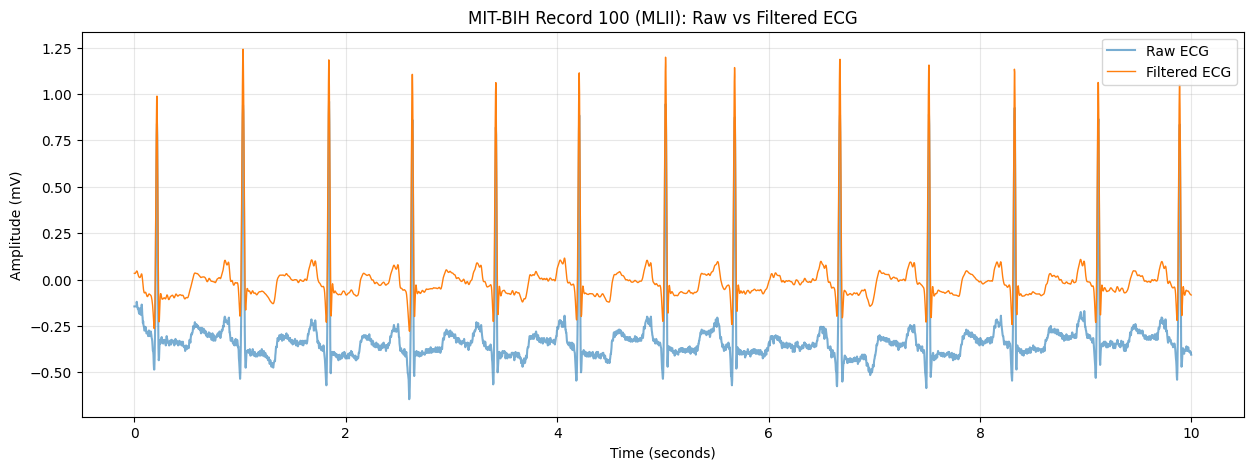

In [5]:
# ============================================================
# LOAD EXAMPLE RECORD
# ============================================================

example_record = "100"

record = wfdb.rdrecord(
    str(
        RAW_DATA_DIR
        / example_record
    )
)

fs = float(
    record.fs
)


# ============================================================
# SELECT PREFERRED ECG CHANNEL
# ============================================================

(
    channel_index,
    channel_name

) = select_preferred_channel(
    record
)


raw_signal = record.p_signal[
    :,
    channel_index
]


print(
    "Available channels:",
    record.sig_name
)

print(
    "Selected channel:",
    channel_name
)


# ============================================================
# FILTER SIGNAL
# ============================================================

filtered_signal = bandpass_filter(
    raw_signal,
    fs
)


# ============================================================
# PLOT FIRST 10 SECONDS
# ============================================================

seconds = 10

n_samples = int(
    seconds
    * fs
)

time = (
    np.arange(n_samples)
    / fs
)


plt.figure(
    figsize=(15, 5)
)

plt.plot(
    time,
    raw_signal[:n_samples],
    label="Raw ECG",
    alpha=0.6
)

plt.plot(
    time,
    filtered_signal[:n_samples],
    label="Filtered ECG",
    linewidth=1
)

plt.xlabel(
    "Time (seconds)"
)

plt.ylabel(
    "Amplitude (mV)"
)

plt.title(
    f"MIT-BIH Record {example_record} "
    f"({channel_name}): Raw vs Filtered ECG"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

### 2.6. Extract Fixed-Length Heartbeat Windows

Reference heartbeat annotations are used as fiducial locations for
heartbeat extraction.

Each retained heartbeat contains exactly 255 ECG samples:

- 128 samples before the annotated fiducial
- 1 sample at the annotated fiducial
- 126 samples after the annotated fiducial

At the MIT-BIH sampling frequency of 360 Hz, the complete heartbeat
window spans:

255 / 360 = 0.708 seconds

Heartbeat windows extending beyond the beginning or end of a recording
are excluded.

Each retained waveform is standardized independently using beat-level
z-score normalization.

In [7]:
# ============================================================
# HEARTBEAT WINDOW SETTINGS
# ============================================================

# Each heartbeat contains:
#
# 128 samples before the annotated fiducial
# 1 annotated fiducial sample
# 126 samples after the annotated fiducial
#
# Total:
#
# 128 + 1 + 126 = 255 samples

SAMPLES_BEFORE_R = 128

SAMPLES_AFTER_R = 126

FIDUCIAL_SAMPLES = 1


HEARTBEAT_LENGTH = (
    SAMPLES_BEFORE_R
    + FIDUCIAL_SAMPLES
    + SAMPLES_AFTER_R
)


assert HEARTBEAT_LENGTH == 255


# ============================================================
# RR CONTEXT SETTINGS
# ============================================================

# Maximum number of previous RR intervals used
# to characterize recent rhythm.

RR_HISTORY = 10


# Minimum number of historical RR intervals required
# before local rhythm statistics are calculated.

MIN_RR_HISTORY = 3


# ============================================================
# MORPHOLOGY CONTEXT SETTINGS
# ============================================================

# Maximum number of previous heartbeat waveforms used
# to construct the local morphology template.

MORPH_HISTORY = 5


# Minimum number of previous valid waveforms required
# to construct the local morphology template.

MIN_MORPH_HISTORY = 3


# ============================================================
# SIX IMMEDIATE RR FEATURES
# ============================================================

RR_FEATURE_NAMES = [

    "rr_pre_sec",

    "rr_post_sec",

    "rr_local_median_sec",

    "rr_pre_norm",

    "rr_post_norm",

    "rr_pre_post_ratio",
]


# ============================================================
# THREE RHYTHM-HISTORY FEATURES
# ============================================================

RHYTHM_FEATURE_NAMES = [

    "rr_history_mean_sec",

    "rr_history_std_sec",

    "rr_history_cv",
]


# ============================================================
# FOUR MORPHOLOGY-CONTEXT FEATURES
# ============================================================

MORPH_CONTEXT_FEATURE_NAMES = [

    "morph_corr_prev",

    "morph_dist_prev",

    "morph_corr_template",

    "morph_dist_template",
]


# ============================================================
# THIRTEEN CONTEXT FEATURES
# ============================================================

CONTEXT_FEATURE_NAMES = (

    RR_FEATURE_NAMES

    + RHYTHM_FEATURE_NAMES

    + MORPH_CONTEXT_FEATURE_NAMES
)


# ============================================================
# VERIFY FEATURE GROUP SIZES
# ============================================================

assert len(
    RR_FEATURE_NAMES
) == 6


assert len(
    RHYTHM_FEATURE_NAMES
) == 3


assert len(
    MORPH_CONTEXT_FEATURE_NAMES
) == 4


assert len(
    CONTEXT_FEATURE_NAMES
) == 13


# ============================================================
# NORMALIZATION FUNCTION
# ============================================================

def normalize_beat(beat):
    """
    Apply heartbeat-level z-score normalization.
    """

    mean = np.mean(
        beat
    )

    std = np.std(
        beat
    )


    if std < 1e-8:

        return (
            beat
            - mean
        )


    return (
        beat
        - mean
    ) / std


# ============================================================
# EXTRACT ONE 255-SAMPLE HEARTBEAT
# ============================================================

def extract_heartbeat_window(
    signal,
    sample
):
    """
    Extract one fixed 255-sample heartbeat window.
    """

    start = (
        int(sample)
        - SAMPLES_BEFORE_R
    )


    # Python slicing excludes the endpoint.
    #
    # sample + 126 + 1
    # gives an exclusive endpoint of sample + 127.

    end = (
        int(sample)
        + SAMPLES_AFTER_R
        + 1
    )


    # --------------------------------------------------------
    # Reject incomplete windows
    # --------------------------------------------------------

    if (
        start < 0
        or end > len(signal)
    ):

        return None


    beat = signal[
        start:end
    ]


    if len(beat) != HEARTBEAT_LENGTH:

        return None


    beat = normalize_beat(
        beat
    )


    return beat.astype(
        np.float32
    )


# ============================================================
# MORPHOLOGY CORRELATION
# ============================================================

def morphology_correlation(
    beat_a,
    beat_b
):
    """
    Pearson correlation between two normalized
    heartbeat waveforms.
    """

    if (
        beat_a is None
        or beat_b is None
    ):

        return np.nan


    if len(beat_a) != len(beat_b):

        return np.nan


    if (
        np.std(beat_a) < 1e-8
        or np.std(beat_b) < 1e-8
    ):

        return np.nan


    return float(
        np.corrcoef(
            beat_a,
            beat_b
        )[0, 1]
    )


# ============================================================
# MORPHOLOGY DISTANCE
# ============================================================

def morphology_distance(
    beat_a,
    beat_b
):
    """
    Root-mean-square distance between two normalized
    heartbeat waveforms.
    """

    if (
        beat_a is None
        or beat_b is None
    ):

        return np.nan


    if len(beat_a) != len(beat_b):

        return np.nan


    difference = (
        beat_a
        - beat_b
    )


    return float(
        np.sqrt(
            np.mean(
                difference ** 2
            )
        )
    )


# ============================================================
# DISPLAY CONFIGURATION
# ============================================================

print(
    "Heartbeat length:",
    HEARTBEAT_LENGTH
)

print(
    "RR features:",
    len(RR_FEATURE_NAMES)
)

print(
    "Rhythm-history features:",
    len(RHYTHM_FEATURE_NAMES)
)

print(
    "Morphology-context features:",
    len(MORPH_CONTEXT_FEATURE_NAMES)
)

print(
    "Total context features:",
    len(CONTEXT_FEATURE_NAMES)
)


print(
    "\nRR features:"
)

print(
    RR_FEATURE_NAMES
)


print(
    "\n13 context features:"
)

print(
    CONTEXT_FEATURE_NAMES
)

Heartbeat length: 255
RR features: 6
Rhythm-history features: 3
Morphology-context features: 4
Total context features: 13

RR features:
['rr_pre_sec', 'rr_post_sec', 'rr_local_median_sec', 'rr_pre_norm', 'rr_post_norm', 'rr_pre_post_ratio']

13 context features:
['rr_pre_sec', 'rr_post_sec', 'rr_local_median_sec', 'rr_pre_norm', 'rr_post_norm', 'rr_pre_post_ratio', 'rr_history_mean_sec', 'rr_history_std_sec', 'rr_history_cv', 'morph_corr_prev', 'morph_dist_prev', 'morph_corr_template', 'morph_dist_template']


### Create dataset-building function

In [11]:
# ============================================================
# BUILD HEARTBEAT DATASET
# ============================================================

def extract_record_beats(
    record_name
):
    """
    Extract N/S/V/F heartbeat windows together with:

    - 6 immediate RR features
    - 3 rhythm-history features
    - 4 morphology-context features

    from one MIT-BIH record.

    Every retained target heartbeat is assigned a permanent
    beat_uid so that all later feature stages can be verified
    to contain the exact same heartbeat rows.
    """

    # ========================================================
    # STEP 1: LOAD ECG AND ANNOTATIONS
    # ========================================================

    record_path = (
        RAW_DATA_DIR
        / record_name
    )


    record = wfdb.rdrecord(
        str(record_path)
    )


    annotation = wfdb.rdann(
        str(record_path),
        "atr"
    )


    fs = float(
        record.fs
    )


    if int(fs) != 360:

        raise ValueError(
            f"Expected MIT-BIH sampling rate of 360 Hz, "
            f"got {fs} for record {record_name}."
        )


    # ========================================================
    # STEP 2: SELECT ECG LEAD
    # ========================================================

    (
        channel_index,
        channel_name

    ) = select_preferred_channel(
        record
    )


    signal = record.p_signal[
        :,
        channel_index
    ]


    # ========================================================
    # STEP 3: FILTER ECG
    # ========================================================

    signal = bandpass_filter(
        signal,
        fs
    )


    # ========================================================
    # STEP 4: FIND ALL HEARTBEAT EVENTS USED FOR RR TIMING
    # ========================================================

    rr_beat_indices = [
        i
        for i, symbol in enumerate(
            annotation.symbol
        )
        if symbol in RR_BEAT_SYMBOLS
    ]


    rr_beat_samples = (
        annotation.sample[
            rr_beat_indices
        ]
    )


    rr_position_by_annotation_index = {
        ann_index: position
        for position, ann_index
        in enumerate(
            rr_beat_indices
        )
    }


    # ========================================================
    # STEP 5: FIND N/S/V/F TARGET HEARTBEATS
    # ========================================================

    target_indices = [
        i
        for i, symbol in enumerate(
            annotation.symbol
        )
        if symbol in AAMI_MAP
    ]


    # ========================================================
    # STEP 6: PRECOMPUTE VALID 255-SAMPLE HEARTBEAT WINDOWS
    # ========================================================

    rr_waveforms = {}


    for (
        rr_position,
        sample

    ) in enumerate(
        rr_beat_samples
    ):

        beat = extract_heartbeat_window(
            signal,
            sample
        )


        if beat is not None:

            rr_waveforms[
                rr_position
            ] = beat


    # ========================================================
    # STEP 7: INITIALIZE OUTPUT
    # ========================================================

    beats = []
    labels = []
    metadata = []


    # ========================================================
    # STEP 8: PROCESS EACH TARGET HEARTBEAT
    # ========================================================

    for ann_index in target_indices:

        sample = int(
            annotation.sample[
                ann_index
            ]
        )


        symbol = (
            annotation.symbol[
                ann_index
            ]
        )


        label = AAMI_MAP[
            symbol
        ]


        rr_position = (
            rr_position_by_annotation_index[
                ann_index
            ]
        )


        beat = rr_waveforms.get(
            rr_position
        )


        # ----------------------------------------------------
        # Exclude target beats whose complete 255-sample
        # waveform could not be extracted.
        # ----------------------------------------------------

        if beat is None:

            continue


        # ====================================================
        # FEATURE 1: PREVIOUS RR INTERVAL
        # ====================================================

        if rr_position > 0:

            rr_pre_sec = (
                rr_beat_samples[
                    rr_position
                ]
                - rr_beat_samples[
                    rr_position - 1
                ]
            ) / fs

        else:

            rr_pre_sec = np.nan


        # ====================================================
        # FEATURE 2: FOLLOWING RR INTERVAL
        # ====================================================

        if rr_position < (
            len(rr_beat_samples)
            - 1
        ):

            rr_post_sec = (
                rr_beat_samples[
                    rr_position + 1
                ]
                - rr_beat_samples[
                    rr_position
                ]
            ) / fs

        else:

            rr_post_sec = np.nan


        # ====================================================
        # PREVIOUS RR HISTORY
        # ====================================================

        history_start = max(
            0,
            rr_position
            - (RR_HISTORY + 1)
        )


        # The interval immediately ending at the current
        # heartbeat is excluded from the historical baseline.
        #
        # Therefore the local reference uses only rhythm
        # completed before the current heartbeat.

        history_samples = (
            rr_beat_samples[
                history_start:
                rr_position
            ]
        )


        if len(history_samples) >= (
            MIN_RR_HISTORY + 1
        ):

            rr_history = (
                np.diff(
                    history_samples
                )
                / fs
            ).astype(
                np.float64
            )


            # ================================================
            # FEATURE 3: LOCAL MEDIAN RR
            # ================================================

            rr_local_median_sec = float(
                np.median(
                    rr_history
                )
            )


            # ================================================
            # FEATURE 7: RR HISTORY MEAN
            # ================================================

            rr_history_mean_sec = float(
                np.mean(
                    rr_history
                )
            )


            # ================================================
            # FEATURE 8: RR HISTORY STANDARD DEVIATION
            # ================================================

            rr_history_std_sec = float(
                np.std(
                    rr_history
                )
            )


            # ================================================
            # FEATURE 9: RR HISTORY COEFFICIENT OF VARIATION
            # ================================================

            if rr_history_mean_sec > 0:

                rr_history_cv = (
                    rr_history_std_sec
                    / rr_history_mean_sec
                )

            else:

                rr_history_cv = np.nan


        else:

            rr_local_median_sec = np.nan

            rr_history_mean_sec = np.nan

            rr_history_std_sec = np.nan

            rr_history_cv = np.nan


        # ====================================================
        # FEATURE 4: NORMALIZED PREVIOUS RR
        # FEATURE 5: NORMALIZED FOLLOWING RR
        # ====================================================

        if (
            np.isfinite(
                rr_local_median_sec
            )
            and rr_local_median_sec > 0
        ):

            if np.isfinite(
                rr_pre_sec
            ):

                rr_pre_norm = (
                    rr_pre_sec
                    / rr_local_median_sec
                )

            else:

                rr_pre_norm = np.nan


            if np.isfinite(
                rr_post_sec
            ):

                rr_post_norm = (
                    rr_post_sec
                    / rr_local_median_sec
                )

            else:

                rr_post_norm = np.nan


        else:

            rr_pre_norm = np.nan

            rr_post_norm = np.nan


        # ====================================================
        # FEATURE 6: PREVIOUS / FOLLOWING RR RATIO
        # ====================================================

        if (
            np.isfinite(
                rr_pre_sec
            )
            and np.isfinite(
                rr_post_sec
            )
            and rr_post_sec > 0
        ):

            rr_pre_post_ratio = (
                rr_pre_sec
                / rr_post_sec
            )

        else:

            rr_pre_post_ratio = np.nan


        # ====================================================
        # FEATURES 10 AND 11:
        # MORPHOLOGY RELATIVE TO PREVIOUS HEARTBEAT
        # ====================================================

        previous_beat = (
            rr_waveforms.get(
                rr_position - 1
            )
        )


        morph_corr_prev = (
            morphology_correlation(
                beat,
                previous_beat
            )
        )


        morph_dist_prev = (
            morphology_distance(
                beat,
                previous_beat
            )
        )


        # ====================================================
        # BUILD LOCAL MORPHOLOGY TEMPLATE
        # ====================================================

        morph_start = max(
            0,
            rr_position
            - MORPH_HISTORY
        )


        previous_positions = range(
            morph_start,
            rr_position
        )


        template_beats = [
            rr_waveforms[position]
            for position
            in previous_positions
            if position in rr_waveforms
        ]


        if len(template_beats) >= (
            MIN_MORPH_HISTORY
        ):

            local_template = (
                np.median(
                    np.stack(
                        template_beats,
                        axis=0
                    ),
                    axis=0
                )
                .astype(
                    np.float32
                )
            )


            # ================================================
            # FEATURE 12:
            # CORRELATION WITH LOCAL MORPHOLOGY TEMPLATE
            # ================================================

            morph_corr_template = (
                morphology_correlation(
                    beat,
                    local_template
                )
            )


            # ================================================
            # FEATURE 13:
            # DISTANCE FROM LOCAL MORPHOLOGY TEMPLATE
            # ================================================

            morph_dist_template = (
                morphology_distance(
                    beat,
                    local_template
                )
            )


        else:

            morph_corr_template = np.nan

            morph_dist_template = np.nan


        # ====================================================
        # CREATE PERMANENT HEARTBEAT IDENTIFIER
        # ====================================================

        beat_uid = (
            f"{record_name}:"
            f"{ann_index}:"
            f"{sample}"
        )


        # ====================================================
        # STORE HEARTBEAT
        # ====================================================

        beats.append(
            beat.astype(
                np.float32
            )
        )


        labels.append(
            label
        )


        # ====================================================
        # STORE METADATA AND CONTEXT FEATURES
        # ====================================================

        metadata.append({

            # ------------------------------------------------
            # CANONICAL HEARTBEAT IDENTIFIERS
            # ------------------------------------------------

            "beat_uid":
                beat_uid,

            "record_id":
                record_name,

            "annotation_index":
                int(
                    ann_index
                ),

            "rr_position":
                int(
                    rr_position
                ),

            "sample":
                sample,

            "sampling_frequency":
                fs,

            "lead":
                channel_name,

            "annotation_symbol":
                symbol,

            "class":
                label,


            # ------------------------------------------------
            # SIX IMMEDIATE RR FEATURES
            # ------------------------------------------------

            "rr_pre_sec":
                rr_pre_sec,

            "rr_post_sec":
                rr_post_sec,

            "rr_local_median_sec":
                rr_local_median_sec,

            "rr_pre_norm":
                rr_pre_norm,

            "rr_post_norm":
                rr_post_norm,

            "rr_pre_post_ratio":
                rr_pre_post_ratio,


            # ------------------------------------------------
            # THREE RHYTHM-HISTORY FEATURES
            # ------------------------------------------------

            "rr_history_mean_sec":
                rr_history_mean_sec,

            "rr_history_std_sec":
                rr_history_std_sec,

            "rr_history_cv":
                rr_history_cv,


            # ------------------------------------------------
            # FOUR MORPHOLOGY-CONTEXT FEATURES
            # ------------------------------------------------

            "morph_corr_prev":
                morph_corr_prev,

            "morph_dist_prev":
                morph_dist_prev,

            "morph_corr_template":
                morph_corr_template,

            "morph_dist_template":
                morph_dist_template,
        })


    # ========================================================
    # RETURN RECORD DATA
    # ========================================================

    return (
        beats,
        labels,
        metadata
    )

### 2.4. Build the Processed ECG Dataset

Heartbeat extraction will now be performed separately for training and testing patient groups.

This separation must occur before machine-learning model training to prevent patient leakage.

In [12]:
# ============================================================
# BUILD DATASET FROM MULTIPLE RECORDS
# ============================================================

def build_dataset(
    record_list
):
    """
    Extract canonical heartbeat rows from a list of
    MIT-BIH records.

    Returns
    -------
    X_ecg : np.ndarray
        Standardized ECG heartbeat waveforms with shape
        (n_beats, 255).

    y : np.ndarray
        N/S/V/F heartbeat labels.

    metadata_df : pd.DataFrame
        Canonical heartbeat identifiers, record metadata,
        and 13 context features.
    """

    all_beats = []
    all_labels = []
    all_metadata = []


    # ========================================================
    # PROCESS RECORDS IN THE PROVIDED ORDER
    # ========================================================

    for record_name in record_list:

        print(
            f"Processing record {record_name}..."
        )


        (
            beats,
            labels,
            metadata

        ) = extract_record_beats(
            record_name
        )


        all_beats.extend(
            beats
        )

        all_labels.extend(
            labels
        )

        all_metadata.extend(
            metadata
        )


    # ========================================================
    # VERIFY THAT DATA WERE EXTRACTED
    # ========================================================

    if len(all_beats) == 0:

        raise ValueError(
            "No heartbeat windows were extracted."
        )


    # ========================================================
    # CONVERT TO CANONICAL ARRAYS
    # ========================================================

    X_ecg = np.stack(
        all_beats,
        axis=0
    ).astype(
        np.float32
    )


    y = np.asarray(
        all_labels,
        dtype=str
    )


    metadata_df = pd.DataFrame(
        all_metadata
    )


    # ========================================================
    # VERIFY ROW ALIGNMENT
    # ========================================================

    assert (
        len(X_ecg)
        == len(y)
        == len(metadata_df)
    )


    assert (
        X_ecg.shape[1]
        == HEARTBEAT_LENGTH
    )


    assert (
        metadata_df[
            "beat_uid"
        ]
        .is_unique
    )


    assert np.array_equal(
        y,
        metadata_df[
            "class"
        ]
        .to_numpy()
    )


    # ========================================================
    # RETURN CANONICAL DATASET
    # ========================================================

    return (
        X_ecg,
        y,
        metadata_df
    )

In [13]:
# ============================================================
# BUILD CANONICAL DS1 DEVELOPMENT DATASET
# ============================================================

X_ds1_ecg, y_ds1, ds1_metadata = build_dataset(
    DS1_RECORDS
)


# ============================================================
# BUILD CANONICAL DS2 EVALUATION DATASET
# ============================================================

X_ds2_ecg, y_ds2, ds2_metadata = build_dataset(
    DS2_RECORDS
)


# ============================================================
# BUILD SIX-RR FEATURE MATRICES
# ============================================================

X_ds1_rr6 = (
    ds1_metadata[
        RR_FEATURE_NAMES
    ]
    .to_numpy(
        dtype=np.float32
    )
)


X_ds2_rr6 = (
    ds2_metadata[
        RR_FEATURE_NAMES
    ]
    .to_numpy(
        dtype=np.float32
    )
)


# ============================================================
# BUILD THIRTEEN-CONTEXT FEATURE MATRICES
# ============================================================

X_ds1_context13 = (
    ds1_metadata[
        CONTEXT_FEATURE_NAMES
    ]
    .to_numpy(
        dtype=np.float32
    )
)


X_ds2_context13 = (
    ds2_metadata[
        CONTEXT_FEATURE_NAMES
    ]
    .to_numpy(
        dtype=np.float32
    )
)


# ============================================================
# VERIFY DS1 ROW ALIGNMENT
# ============================================================

assert (
    len(X_ds1_ecg)
    == len(y_ds1)
    == len(ds1_metadata)
    == len(X_ds1_rr6)
    == len(X_ds1_context13)
)


# ============================================================
# VERIFY DS2 ROW ALIGNMENT
# ============================================================

assert (
    len(X_ds2_ecg)
    == len(y_ds2)
    == len(ds2_metadata)
    == len(X_ds2_rr6)
    == len(X_ds2_context13)
)


# ============================================================
# VERIFY UNIQUE HEARTBEAT IDENTIFIERS
# ============================================================

assert (
    ds1_metadata[
        "beat_uid"
    ]
    .is_unique
)


assert (
    ds2_metadata[
        "beat_uid"
    ]
    .is_unique
)


# ============================================================
# VERIFY NO HEARTBEAT UID EXISTS IN BOTH DATASETS
# ============================================================

beat_uid_overlap = (
    set(
        ds1_metadata[
            "beat_uid"
        ]
    )
    .intersection(
        set(
            ds2_metadata[
                "beat_uid"
            ]
        )
    )
)


assert len(
    beat_uid_overlap
) == 0


# ============================================================
# VERIFY LABEL ALIGNMENT
# ============================================================

assert np.array_equal(
    y_ds1,
    ds1_metadata[
        "class"
    ]
    .to_numpy()
)


assert np.array_equal(
    y_ds2,
    ds2_metadata[
        "class"
    ]
    .to_numpy()
)


# ============================================================
# VERIFY FEATURE DIMENSIONS
# ============================================================

assert (
    X_ds1_ecg.shape[1]
    == 255
)

assert (
    X_ds2_ecg.shape[1]
    == 255
)


assert (
    X_ds1_rr6.shape[1]
    == 6
)

assert (
    X_ds2_rr6.shape[1]
    == 6
)


assert (
    X_ds1_context13.shape[1]
    == 13
)

assert (
    X_ds2_context13.shape[1]
    == 13
)


# ============================================================
# DISPLAY CANONICAL DATASET SHAPES
# ============================================================

print(
    "\nDS1 ECG:",
    X_ds1_ecg.shape
)

print(
    "DS1 RR6:",
    X_ds1_rr6.shape
)

print(
    "DS1 Context13:",
    X_ds1_context13.shape
)

print(
    "DS1 labels:",
    y_ds1.shape
)


print(
    "\nDS2 ECG:",
    X_ds2_ecg.shape
)

print(
    "DS2 RR6:",
    X_ds2_rr6.shape
)

print(
    "DS2 Context13:",
    X_ds2_context13.shape
)

print(
    "DS2 labels:",
    y_ds2.shape
)


print(
    "\nCanonical heartbeat row alignment verified."
)

Processing record 101...
Processing record 106...
Processing record 108...
Processing record 109...
Processing record 112...
Processing record 114...
Processing record 115...
Processing record 116...
Processing record 118...
Processing record 119...
Processing record 122...
Processing record 124...
Processing record 201...
Processing record 203...
Processing record 205...
Processing record 207...
Processing record 208...
Processing record 209...
Processing record 215...
Processing record 220...
Processing record 223...
Processing record 230...
Processing record 100...
Processing record 103...
Processing record 105...
Processing record 111...
Processing record 113...
Processing record 117...
Processing record 121...
Processing record 123...
Processing record 200...
Processing record 202...
Processing record 210...
Processing record 212...
Processing record 213...
Processing record 214...
Processing record 219...
Processing record 221...
Processing record 222...
Processing record 228...


### Verify no patient leakage

In [14]:
# ============================================================
# VERIFY RECORD-LEVEL SEPARATION
# ============================================================

ds1_records_present = set(
    ds1_metadata[
        "record_id"
    ]
)


ds2_records_present = set(
    ds2_metadata[
        "record_id"
    ]
)


record_overlap = (
    ds1_records_present
    .intersection(
        ds2_records_present
    )
)


# ============================================================
# DISPLAY RECORD SUMMARY
# ============================================================

print(
    "Number of DS1 records:",
    len(ds1_records_present)
)

print(
    "Number of DS2 records:",
    len(ds2_records_present)
)

print(
    "Record overlap:",
    record_overlap
)


# ============================================================
# VERIFY EXPECTED RECORD COUNTS
# ============================================================

assert (
    len(ds1_records_present)
    == 22
)


assert (
    len(ds2_records_present)
    == 22
)


# ============================================================
# VERIFY NO RECORD ID OVERLAP
# ============================================================

assert len(
    record_overlap
) == 0, (
    "Record overlap detected between DS1 and DS2."
)


print(
    "\nRecord-level separation verified."
)


# ============================================================
# DOCUMENT SUBJECT-SHARING EXCEPTION
# ============================================================

print(
    "\nImportant:"
)

print(
    "MIT-BIH records 201 and 202 were obtained "
    "from the same subject."
)

print(
    "Therefore this partition is record-disjoint, "
    "not strictly subject-disjoint."
)

Number of DS1 records: 22
Number of DS2 records: 22
Record overlap: set()

Record-level separation verified.

Important:
MIT-BIH records 201 and 202 were obtained from the same subject.
Therefore this partition is record-disjoint, not strictly subject-disjoint.


### Examine class imbalance

In [15]:
# ============================================================
# DS1 CLASS DISTRIBUTION
# ============================================================

ds1_distribution = (
    pd.Series(
        y_ds1
    )
    .value_counts()
    .reindex(
        CLASS_NAMES,
        fill_value=0
    )
)


# ============================================================
# DS2 CLASS DISTRIBUTION
# ============================================================

ds2_distribution = (
    pd.Series(
        y_ds2
    )
    .value_counts()
    .reindex(
        CLASS_NAMES,
        fill_value=0
    )
)


# ============================================================
# CALCULATE CLASS PERCENTAGES
# ============================================================

ds1_percentage = (
    100
    * ds1_distribution
    / ds1_distribution.sum()
)


ds2_percentage = (
    100
    * ds2_distribution
    / ds2_distribution.sum()
)


# ============================================================
# BUILD SUMMARY TABLE
# ============================================================

distribution_df = pd.DataFrame(
    {
        "DS1_count":
            ds1_distribution,

        "DS1_percent":
            ds1_percentage,

        "DS2_count":
            ds2_distribution,

        "DS2_percent":
            ds2_percentage,
    }
)


display(
    distribution_df
)


# ============================================================
# DISPLAY TOTALS
# ============================================================

print(
    "DS1 total:",
    int(
        ds1_distribution.sum()
    )
)


print(
    "DS2 total:",
    int(
        ds2_distribution.sum()
    )
)

,DS1_count,DS1_percent,DS2_count,DS2_percent
N,45846,89.908221,44241,89.041179
S,944,1.851271,1837,3.697219
V,3788,7.428616,3220,6.480699
F,414,0.811892,388,0.780904


DS1 total: 50992
DS2 total: 49686


### Save processed data

In [16]:
# ============================================================
# SAVE CANONICAL ECG WAVEFORMS
# ============================================================

np.save(
    PROCESSED_DATA_DIR
    / "X_ds1_ecg.npy",
    X_ds1_ecg
)


np.save(
    PROCESSED_DATA_DIR
    / "X_ds2_ecg.npy",
    X_ds2_ecg
)


# ============================================================
# SAVE CANONICAL LABELS
# ============================================================

np.save(
    PROCESSED_DATA_DIR
    / "y_ds1.npy",
    y_ds1
)


np.save(
    PROCESSED_DATA_DIR
    / "y_ds2.npy",
    y_ds2
)


# ============================================================
# SAVE SIX IMMEDIATE RR FEATURES
# ============================================================

np.save(
    PROCESSED_DATA_DIR
    / "X_ds1_rr6.npy",
    X_ds1_rr6
)


np.save(
    PROCESSED_DATA_DIR
    / "X_ds2_rr6.npy",
    X_ds2_rr6
)


# ============================================================
# SAVE THIRTEEN CONTEXT FEATURES
# ============================================================

np.save(
    PROCESSED_DATA_DIR
    / "X_ds1_context13.npy",
    X_ds1_context13
)


np.save(
    PROCESSED_DATA_DIR
    / "X_ds2_context13.npy",
    X_ds2_context13
)


# ============================================================
# SAVE SIX-RR FEATURE NAMES
# ============================================================

np.save(
    PROCESSED_DATA_DIR
    / "rr6_feature_names.npy",

    np.asarray(
        RR_FEATURE_NAMES,
        dtype=str
    )
)


# ============================================================
# SAVE THIRTEEN-CONTEXT FEATURE NAMES
# ============================================================

np.save(
    PROCESSED_DATA_DIR
    / "context13_feature_names.npy",

    np.asarray(
        CONTEXT_FEATURE_NAMES,
        dtype=str
    )
)


# ============================================================
# SAVE CANONICAL HEARTBEAT METADATA
# ============================================================

ds1_metadata.to_csv(
    PROCESSED_DATA_DIR
    / "ds1_metadata.csv",
    index=False
)


ds2_metadata.to_csv(
    PROCESSED_DATA_DIR
    / "ds2_metadata.csv",
    index=False
)


# ============================================================
# VERIFY SAVED COMPONENT DIMENSIONS
# ============================================================

print(
    "Saved canonical preprocessing outputs:"
)

print(
    "\nDS1 ECG:",
    X_ds1_ecg.shape
)

print(
    "DS1 RR6:",
    X_ds1_rr6.shape
)

print(
    "DS1 Context13:",
    X_ds1_context13.shape
)


print(
    "\nDS2 ECG:",
    X_ds2_ecg.shape
)

print(
    "DS2 RR6:",
    X_ds2_rr6.shape
)

print(
    "DS2 Context13:",
    X_ds2_context13.shape
)


print(
    "\nCanonical preprocessing data saved successfully."
)

Saved canonical preprocessing outputs:

DS1 ECG: (50992, 255)
DS1 RR6: (50992, 6)
DS1 Context13: (50992, 13)

DS2 ECG: (49686, 255)
DS2 RR6: (49686, 6)
DS2 Context13: (49686, 13)

Canonical preprocessing data saved successfully.


In [17]:
# ============================================================
# FIXED DS1 CROSS-VALIDATION SETTINGS
# ============================================================

N_SPLITS = 5

MAX_SEEDS_TO_TRY = 1000


FOLD_PATH = (
    PROCESSED_DATA_DIR
    / "ds1_cv_record_folds.csv"
)


# ============================================================
# DEFINE DS1 RECORD GROUPS
# ============================================================

ds1_groups = (
    ds1_metadata[
        "record_id"
    ]
    .to_numpy()
)


# ============================================================
# CHECK WHETHER FIXED FOLDS ALREADY EXIST
# ============================================================

if FOLD_PATH.exists():

    print(
        "Existing fixed DS1 folds found."
    )

    print(
        "Loading:",
        FOLD_PATH
    )


    saved_record_folds = pd.read_csv(
        FOLD_PATH,
        dtype={
            "record_id": str,
            "cv_fold": int,
        }
    )


    # --------------------------------------------------------
    # Verify saved records match current DS1 records
    # --------------------------------------------------------

    current_records = set(
        ds1_metadata[
            "record_id"
        ]
        .unique()
    )


    saved_records = set(
        saved_record_folds[
            "record_id"
        ]
    )


    assert (
        current_records
        == saved_records
    ), (
        "Saved fold records do not match "
        "the current canonical DS1 dataset."
    )


    # --------------------------------------------------------
    # Verify each record has exactly one fold
    # --------------------------------------------------------

    assert (
        saved_record_folds[
            "record_id"
        ]
        .is_unique
    )


    assert set(
        saved_record_folds[
            "cv_fold"
        ]
    ) == set(
        range(
            1,
            N_SPLITS + 1
        )
    )


    # --------------------------------------------------------
    # Map saved folds onto every canonical heartbeat row
    # --------------------------------------------------------

    fold_map = dict(
        zip(
            saved_record_folds[
                "record_id"
            ],
            saved_record_folds[
                "cv_fold"
            ]
        )
    )


    ds1_metadata[
        "cv_fold"
    ] = (
        ds1_metadata[
            "record_id"
        ]
        .map(
            fold_map
        )
        .astype(
            int
        )
    )


    selected_cv_seed = None


# ============================================================
# OTHERWISE GENERATE A VALID FIXED ASSIGNMENT
# ============================================================

else:

    print(
        "No saved fold assignment found."
    )

    print(
        "Searching for a valid five-fold "
        "record-grouped assignment..."
    )


    best_score = np.inf

    best_assignment = None

    selected_cv_seed = None


    # ========================================================
    # SEARCH CANDIDATE RANDOM SEEDS
    # ========================================================

    for candidate_seed in range(
        MAX_SEEDS_TO_TRY
    ):

        splitter = StratifiedGroupKFold(
            n_splits=N_SPLITS,
            shuffle=True,
            random_state=candidate_seed
        )


        candidate_assignment = np.full(
            len(y_ds1),
            fill_value=-1,
            dtype=np.int32
        )


        fold_sizes = []

        fold_class_proportions = []

        valid_candidate = True


        # ====================================================
        # BUILD CANDIDATE FOLDS
        # ====================================================

        for fold_number, (
            train_indices,
            validation_indices

        ) in enumerate(
            splitter.split(
                X_ds1_ecg,
                y_ds1,
                groups=ds1_groups
            ),
            start=1
        ):

            validation_labels = (
                y_ds1[
                    validation_indices
                ]
            )


            class_counts = (
                pd.Series(
                    validation_labels
                )
                .value_counts()
                .reindex(
                    CLASS_NAMES,
                    fill_value=0
                )
            )


            # ------------------------------------------------
            # Require N/S/V/F in every validation fold
            # ------------------------------------------------

            if (
                class_counts
                == 0
            ).any():

                valid_candidate = False

                break


            candidate_assignment[
                validation_indices
            ] = fold_number


            fold_sizes.append(
                len(
                    validation_indices
                )
            )


            fold_class_proportions.append(
                (
                    class_counts
                    / class_counts.sum()
                )
                .to_numpy(
                    dtype=float
                )
            )


        # ====================================================
        # REJECT INVALID CANDIDATE
        # ====================================================

        if not valid_candidate:

            continue


        if not (
            candidate_assignment
            >= 1
        ).all():

            continue


        # ====================================================
        # VERIFY RECORDS ARE NOT SPLIT ACROSS FOLDS
        # ====================================================

        candidate_df = pd.DataFrame(
            {
                "record_id":
                    ds1_groups,

                "cv_fold":
                    candidate_assignment,
            }
        )


        record_fold_counts = (
            candidate_df
            .drop_duplicates()
            .groupby(
                "record_id"
            )[
                "cv_fold"
            ]
            .nunique()
        )


        if not (
            record_fold_counts
            == 1
        ).all():

            continue


        # ====================================================
        # SCORE FOLD BALANCE
        # ====================================================

        fold_sizes = np.asarray(
            fold_sizes,
            dtype=float
        )


        fold_class_proportions = np.asarray(
            fold_class_proportions,
            dtype=float
        )


        # Relative spread in fold sizes
        size_score = (
            np.std(
                fold_sizes
            )
            / np.mean(
                fold_sizes
            )
        )


        # Mean variability of class proportions
        class_balance_score = float(
            np.mean(
                np.std(
                    fold_class_proportions,
                    axis=0
                )
            )
        )


        total_score = (
            size_score
            + class_balance_score
        )


        # ====================================================
        # KEEP BEST VALID ASSIGNMENT
        # ====================================================

        if total_score < best_score:

            best_score = total_score

            best_assignment = (
                candidate_assignment.copy()
            )

            selected_cv_seed = (
                candidate_seed
            )


    # ========================================================
    # VERIFY A VALID ASSIGNMENT WAS FOUND
    # ========================================================

    if best_assignment is None:

        raise RuntimeError(
            "Could not find a valid five-fold "
            "record-grouped split containing "
            "N, S, V, and F in every validation fold."
        )


    # ========================================================
    # STORE SELECTED FOLD ASSIGNMENT
    # ========================================================

    ds1_metadata[
        "cv_fold"
    ] = best_assignment


    print(
        "Selected CV seed:",
        selected_cv_seed
    )


    print(
        "Fold-balance score:",
        best_score
    )


# ============================================================
# DISPLAY BEAT COUNTS PER FOLD
# ============================================================

print(
    "\nDS1 heartbeat counts per fold:"
)

print(
    ds1_metadata[
        "cv_fold"
    ]
    .value_counts()
    .sort_index()
)

No saved fold assignment found.
Searching for a valid five-fold record-grouped assignment...
Selected CV seed: 186
Fold-balance score: 0.06226388739466475

DS1 heartbeat counts per fold:
cv_fold
1    10411
2    10491
3    10248
4     9469
5    10373
Name: count, dtype: int64


In [18]:
# ============================================================
# VERIFY FIXED FIVE-FOLD DS1 ASSIGNMENT
# ============================================================

fold_summary_rows = []


for fold_number in range(
    1,
    N_SPLITS + 1
):

    # ========================================================
    # SELECT VALIDATION ROWS FOR THIS FOLD
    # ========================================================

    validation_mask = (
        ds1_metadata[
            "cv_fold"
        ]
        == fold_number
    )


    validation_metadata = (
        ds1_metadata.loc[
            validation_mask
        ]
    )


    validation_labels = (
        y_ds1[
            validation_mask.to_numpy()
        ]
    )


    validation_records = sorted(
        validation_metadata[
            "record_id"
        ]
        .unique()
    )


    # ========================================================
    # CLASS COUNTS
    # ========================================================

    class_counts = (
        pd.Series(
            validation_labels
        )
        .value_counts()
        .reindex(
            CLASS_NAMES,
            fill_value=0
        )
    )


    # ========================================================
    # BUILD SUMMARY ROW
    # ========================================================

    fold_summary_rows.append(
        {
            "fold":
                fold_number,

            "n_records":
                len(
                    validation_records
                ),

            "n_beats":
                len(
                    validation_metadata
                ),

            "N":
                int(
                    class_counts["N"]
                ),

            "S":
                int(
                    class_counts["S"]
                ),

            "V":
                int(
                    class_counts["V"]
                ),

            "F":
                int(
                    class_counts["F"]
                ),

            "records":
                ", ".join(
                    validation_records
                ),
        }
    )


# ============================================================
# CREATE FOLD SUMMARY TABLE
# ============================================================

fold_summary_df = pd.DataFrame(
    fold_summary_rows
)


display(
    fold_summary_df
)


# ============================================================
# VERIFY ALL CLASSES EXIST IN EVERY VALIDATION FOLD
# ============================================================

for class_name in CLASS_NAMES:

    assert (
        fold_summary_df[
            class_name
        ]
        > 0
    ).all(), (
        f"Class {class_name} is missing "
        "from at least one validation fold."
    )


# ============================================================
# VERIFY EACH RECORD BELONGS TO EXACTLY ONE FOLD
# ============================================================

record_fold_table = (
    ds1_metadata[
        [
            "record_id",
            "cv_fold",
        ]
    ]
    .drop_duplicates()
)


record_fold_counts = (
    record_fold_table
    .groupby(
        "record_id"
    )[
        "cv_fold"
    ]
    .nunique()
)


assert (
    record_fold_counts
    == 1
).all(), (
    "At least one ECG record appears "
    "in more than one validation fold."
)


# ============================================================
# VERIFY ALL 22 DS1 RECORDS ARE REPRESENTED
# ============================================================

assert (
    record_fold_table[
        "record_id"
    ]
    .nunique()
    == 22
)


# ============================================================
# VERIFY EVERY DS1 ROW HAS ONE VALID FOLD
# ============================================================

assert (
    ds1_metadata[
        "cv_fold"
    ]
    .between(
        1,
        N_SPLITS
    )
    .all()
)


# ============================================================
# VERIFY TRAIN / VALIDATION RECORD SEPARATION PER FOLD
# ============================================================

for fold_number in range(
    1,
    N_SPLITS + 1
):

    validation_records = set(
        ds1_metadata.loc[
            ds1_metadata[
                "cv_fold"
            ]
            == fold_number,
            "record_id"
        ]
    )


    training_records = set(
        ds1_metadata.loc[
            ds1_metadata[
                "cv_fold"
            ]
            != fold_number,
            "record_id"
        ]
    )


    assert (
        len(
            validation_records
            .intersection(
                training_records
            )
        )
        == 0
    )


print(
    "Fixed five-fold DS1 assignment "
    "verified successfully."
)

,fold,n_records,n_beats,N,S,V,F,records
0,1,5,10411,9378,45,978,10,"114, 115, 119, 124, 203"
1,2,5,10491,9691,334,462,4,"101, 109, 118, 201, 207"
2,3,4,10248,8999,76,1158,15,"106, 215, 223, 230"
3,4,4,9469,8883,484,89,13,"108, 205, 209, 220"
4,5,4,10373,8895,5,1101,372,"112, 116, 122, 208"


Fixed five-fold DS1 assignment verified successfully.


In [19]:
# ============================================================
# BUILD RECORD-LEVEL FIXED FOLD TABLE
# ============================================================

ds1_record_folds = (
    ds1_metadata[
        [
            "record_id",
            "cv_fold",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "cv_fold",
            "record_id",
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# VERIFY EXACTLY 22 RECORD ASSIGNMENTS
# ============================================================

assert len(
    ds1_record_folds
) == 22


assert (
    ds1_record_folds[
        "record_id"
    ]
    .is_unique
)


# ============================================================
# SAVE FIXED RECORD-LEVEL FOLDS
# ============================================================

fold_path = (
    PROCESSED_DATA_DIR
    / "ds1_cv_record_folds.csv"
)


ds1_record_folds.to_csv(
    fold_path,
    index=False
)


# ============================================================
# SAVE FOLD SUMMARY
# ============================================================

fold_summary_path = (
    PROCESSED_DATA_DIR
    / "ds1_cv_fold_summary.csv"
)


fold_summary_df.to_csv(
    fold_summary_path,
    index=False
)


# ============================================================
# RESAVE DS1 METADATA WITH ROW-LEVEL FOLD ASSIGNMENT
# ============================================================

ds1_metadata.to_csv(
    PROCESSED_DATA_DIR
    / "ds1_metadata.csv",
    index=False
)


# ============================================================
# OPTIONAL: SAVE THE SELECTED SEED WHEN GENERATED
# ============================================================

seed_path = (
    PROCESSED_DATA_DIR
    / "ds1_cv_seed.txt"
)


if selected_cv_seed is not None:

    seed_path.write_text(
        str(
            selected_cv_seed
        )
    )


# ============================================================
# DISPLAY FINAL RECORD-LEVEL FOLD ASSIGNMENT
# ============================================================

print(
    "Final fixed DS1 record assignments:"
)

display(
    ds1_record_folds
)


# ============================================================
# FINAL NOTEBOOK 02 SUMMARY
# ============================================================

print(
    "\nNotebook 02 completed successfully."
)

print(
    "\nCanonical experimental components:"
)

print(
    "ECG waveform: 255 samples"
)

print(
    "RR6:          6 features"
)

print(
    "Context13:    13 features"
)

print(
    "\nFixed five-fold DS1 assignments saved to:"
)

print(
    fold_path
)


print(
    "\nFold summary saved to:"
)

print(
    fold_summary_path
)

Final fixed DS1 record assignments:


,record_id,cv_fold
0,114,1
1,115,1
2,119,1
3,124,1
4,203,1
5,101,2
6,109,2
7,118,2
8,201,2
9,207,2



Notebook 02 completed successfully.

Canonical experimental components:
ECG waveform: 255 samples
RR6:          6 features
Context13:    13 features

Fixed five-fold DS1 assignments saved to:
/Users/janusaban/Documents/ML_research/05_ecg-ml/data/processed/ds1_cv_record_folds.csv

Fold summary saved to:
/Users/janusaban/Documents/ML_research/05_ecg-ml/data/processed/ds1_cv_fold_summary.csv
